# TUGAS: Output DAN EVALUASI 5 PROMPT GEOFISIKA
## Framework Rekayasa Prompt: R–T–C–I–K–O–Q–V

---
**Nama:** Naufal Mifzaldy Nurhidayat  
**NIM:** H061251035 
**Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika  
**Departemen Geofisika**  
**Universitas Hasanuddin**

### Daftar Topik
- **Topik 1:** Pemodelan Anomali Gravitasi dari Sumber Bawah Permukaan
- **Topik 2:** Interpretasi Anomali Magnetik terhadap Kedalaman Sumber
- **Topik 3:** Metode Resistivitas Schlumberger untuk Model Dua Lapisan
- **Topik 4:** Analisis Frekuensi Rekaman Getaran Menggunakan FFT
- **Topik 5:** Estimasi Gradien Geotermal dan Aliran Panas

> Catatan: data numerik yang digunakan pada notebook ini merupakan data simulasi untuk latihan, bukan hasil survei lapangan.

# PEMODELAN ANOMALI GRAVITASI DARI SUMBER BAWAH PERMUKAAN

### A. Latar Belakang Teori & Konsep Fisis
Metode gravitasi mengukur perubahan kecil percepatan gravitasi yang dipengaruhi oleh distribusi massa di bawah permukaan. Sebagai pendekatan sederhana, sumber anomali dapat dimodelkan sebagai massa titik.

Anomali gravitasi vertikal ideal dari massa titik dapat dituliskan:

\[
\Delta g(z)=\frac{G\,\Delta m\,z}{(x^2+z^2)^{3/2}}
\]

dengan \(G\) adalah konstanta gravitasi, \(\Delta m\) kontras massa, \(z\) kedalaman sumber, dan \(x\) jarak horizontal dari proyeksi sumber. Dalam latihan ini, respons dihitung sepanjang lintasan permukaan dengan sumber berada pada kedalaman tetap.

### B. Prompt AI (Struktur R–T–C–I–K–O–Q–V)

```markdown
# R — Role
Anda adalah asisten praktikum geofisika yang menjelaskan pemodelan gravitasi secara bertahap.

# T — Task
Hitung dan plot respons gravitasi dari sebuah sumber massa sederhana di bawah permukaan.

# C — Context
Data merupakan simulasi lintasan pengukuran gravitasi dua dimensi.

# I — Input
Jarak horizontal x, kedalaman sumber, kontras massa, dan konstanta gravitasi.

# K — Constraints
Gunakan satuan SI dalam perhitungan dan ubah hasil akhir ke mGal. Jelaskan bahwa model massa titik adalah penyederhanaan.

# O — Output
Tampilkan parameter, grafik anomali, posisi puncak, dan interpretasi awal.

# Q — Quality Criteria
Label sumbu, satuan, dan perhitungan harus konsisten.

# V — Verification
Pastikan respons terbesar berada dekat proyeksi horizontal sumber.
```

Kedalaman sumber: 1200 m
Kontras massa efektif: 2.00e+10 kg
Anomali maksimum: 0.0927 mGal pada x = 0 m


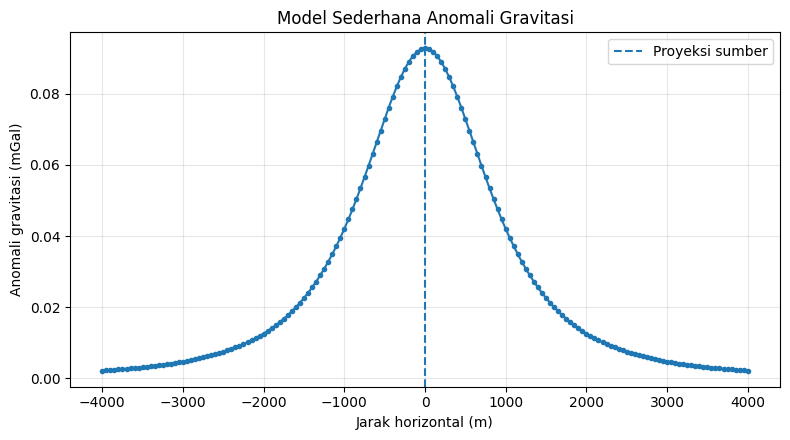

In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = 6.67430e-11             # konstanta gravitasi (m^3 kg^-1 s^-2)
delta_m = 2.0e10            # kontras massa efektif (kg), data simulasi
depth = 1200.0              # kedalaman sumber (m)
x = np.linspace(-4000, 4000, 161)  # jarak horizontal (m)

# Komponen vertikal gravitasi dari massa titik; 1 m/s^2 = 1e5 mGal
r2 = x**2 + depth**2
g_mgal = (G * delta_m * depth / (r2**1.5)) * 1e5

imax = np.argmax(g_mgal)
print(f"Kedalaman sumber: {depth:.0f} m")
print(f"Kontras massa efektif: {delta_m:.2e} kg")
print(f"Anomali maksimum: {g_mgal[imax]:.4f} mGal pada x = {x[imax]:.0f} m")

plt.figure(figsize=(8, 4.5))
plt.plot(x, g_mgal, marker='o', ms=3)
plt.axvline(0, linestyle='--', label='Proyeksi sumber')
plt.xlabel('Jarak horizontal (m)')
plt.ylabel('Anomali gravitasi (mGal)')
plt.title('Model Sederhana Anomali Gravitasi')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### C. Pembahasan Hasil & Verifikasi Mutu Prompt

1. **Analisis hasil:** Kurva memiliki nilai tertinggi di sekitar \(x=0\), yaitu titik yang tepat berada di atas sumber pada model ini. Respons menurun ketika jarak horizontal bertambah karena jarak sumber-pengamat semakin besar.
2. **Makna geofisika:** Bentuk kurva dapat membantu mengenali posisi relatif sumber kontras massa, tetapi amplitudo juga dipengaruhi oleh besar kontras massa dan kedalaman.
3. **Pengecekan mutu (Q & V):**
   - [x] Perhitungan dilakukan dalam satuan SI lalu dikonversi ke mGal.
   - [x] Puncak kurva diperiksa terhadap proyeksi sumber.
   - [x] Interpretasi dibatasi karena geometri sumber nyata dapat lebih kompleks daripada massa titik.

# INTERPRETASI ANOMALI MAGNETIK TERHADAP KEDALAMAN SUMBER

### A. Latar Belakang Teori & Konsep Fisis
Survei magnetik mengukur variasi medan magnet yang berkaitan dengan kemagnetan batuan. Bentuk anomali dipengaruhi oleh geometri, kedalaman, orientasi, dan kontras kemagnetan sumber. Untuk latihan awal, sinyal dapat direpresentasikan sebagai gabungan beberapa komponen sinusoidal.

\[
B(x)=A\cos\left(\frac{2\pi x}{L}\right)
\]

di mana \(A\) adalah amplitudo dan \(L\) adalah panjang gelombang. Panjang gelombang yang lebih panjang sering berkaitan dengan sumber yang lebih dalam atau berskala lebih besar, tetapi hubungan tersebut bukan penentuan kedalaman yang unik.

### B. Prompt AI (Struktur R–T–C–I–K–O–Q–V)

```markdown
# R — Role
Anda adalah pembimbing praktikum metode magnetik.

# T — Task
Buat simulasi anomali magnetik dan bandingkan dua komponen dengan panjang gelombang berbeda.

# C — Context
Data adalah profil sintetik untuk menunjukkan pengaruh skala spasial.

# I — Input
Jarak profil, amplitudo, panjang gelombang, dan gangguan kecil.

# K — Constraints
Jangan menyatakan kedalaman pasti hanya dari panjang gelombang. Gunakan satuan yang jelas.

# O — Output
Grafik profil dan penjelasan perbedaan komponen.

# Q — Quality Criteria
Grafik mudah dibaca dan pembahasan sesuai asumsi model.

# V — Verification
Pastikan komponen panjang gelombang besar berubah lebih lambat sepanjang profil.
```

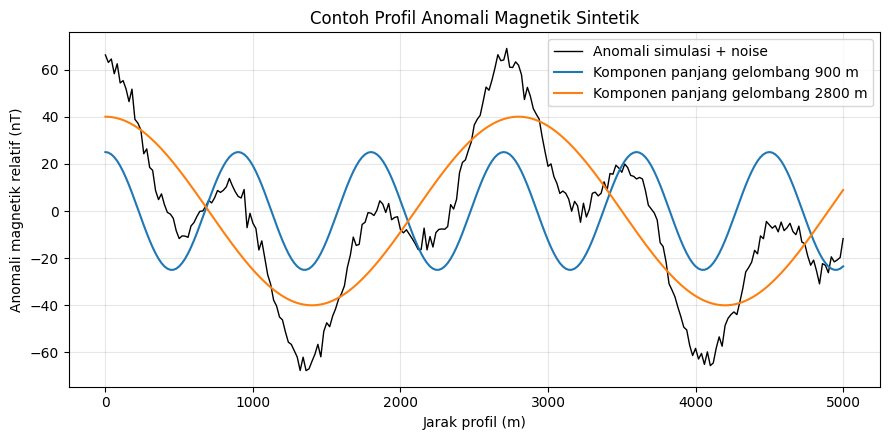

Rentang anomali gabungan: -67.7 hingga 68.9 nT


In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(12)
x = np.linspace(0, 5000, 251)  # profil dalam meter
short_component = 25 * np.cos(2 * np.pi * x / 900)
long_component = 40 * np.cos(2 * np.pi * x / 2800)
noise = np.random.normal(0, 2.5, size=x.size)
observed = short_component + long_component + noise

plt.figure(figsize=(9, 4.5))
plt.plot(x, observed, color='black', lw=1, label='Anomali simulasi + noise')
plt.plot(x, short_component, label='Komponen panjang gelombang 900 m')
plt.plot(x, long_component, label='Komponen panjang gelombang 2800 m')
plt.xlabel('Jarak profil (m)')
plt.ylabel('Anomali magnetik relatif (nT)')
plt.title('Contoh Profil Anomali Magnetik Sintetik')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Rentang anomali gabungan: {observed.min():.1f} hingga {observed.max():.1f} nT")

### C. Pembahasan Hasil & Verifikasi Mutu Prompt

1. **Analisis hasil:** Komponen dengan panjang gelombang 900 m memiliki perubahan yang lebih rapat, sedangkan komponen 2800 m berubah lebih perlahan sepanjang lintasan.
2. **Interpretasi:** Komponen berpanjang gelombang besar dapat mencerminkan struktur berskala lebih luas atau sumber yang lebih dalam. Namun, kedalaman tidak dapat ditentukan hanya dari satu kurva tanpa pemodelan dan informasi tambahan.
3. **Pengecekan mutu (Q & V):**
   - [x] Data dinyatakan sebagai anomali relatif dalam nT.
   - [x] Gangguan acak dibuat dengan seed tetap agar hasil dapat diulang.
   - [x] Tidak ada klaim kedalaman pasti dari panjang gelombang saja.

#  METODE RESISTIVITAS SCHLUMBERGER UNTUK MODEL DUA LAPISAN

### A. Latar Belakang Teori & Konsep Fisis
Metode resistivitas mengukur beda potensial akibat arus listrik yang dialirkan ke dalam tanah. Pada konfigurasi Schlumberger, jarak elektroda arus dibuat lebih besar dibanding jarak elektroda potensial. Untuk susunan simetris dengan \(AB\) sebagai jarak elektroda arus dan \(MN\) sebagai jarak elektroda potensial, faktor geometri ideal adalah:

\[
K=\frac{\pi\left[(AB/2)^2-(MN/2)^2\right]}{MN}
\]

Resistivitas semu dihitung dari \(\rho_a=K\Delta V/I\). Nilai ini merupakan respons gabungan bawah permukaan, bukan selalu resistivitas lapisan tunggal.

### B. Prompt AI (Struktur R–T–C–I–K–O–Q–V)

```markdown
# R — Role
Anda adalah asisten praktikum metode geolistrik.

# T — Task
Hitung resistivitas semu dari data konfigurasi Schlumberger simulasi.

# C — Context
Data dibuat untuk latihan hitungan faktor geometri dan interpretasi awal.

# I — Input
AB, MN, arus I, dan beda potensial ΔV.

# K — Constraints
Gunakan satuan meter, ampere, dan volt; jangan menyamakan resistivitas semu dengan resistivitas sebenarnya secara langsung.

# O — Output
Tabel hasil perhitungan dan grafik resistivitas semu terhadap AB/2.

# Q — Quality Criteria
Rumus faktor geometri dan satuan hasil harus konsisten.

# V — Verification
Pastikan faktor geometri bernilai positif dan resistivitas semu tidak negatif untuk data ini.
```

,AB/2 (m),MN (m),K (m),Delta V (V),I (A),Resistivitas semu (ohm m)
0,5.0,2.0,37.70,0.04,0.1,15.83
1,10.0,2.0,155.51,0.02,0.1,38.88
2,15.0,4.0,173.57,0.03,0.1,53.81
3,20.0,4.0,311.02,0.02,0.1,71.53
4,30.0,6.0,466.53,0.02,0.1,93.31
5,40.0,8.0,622.04,0.02,0.1,111.97
6,50.0,10.0,777.54,0.02,0.1,124.41


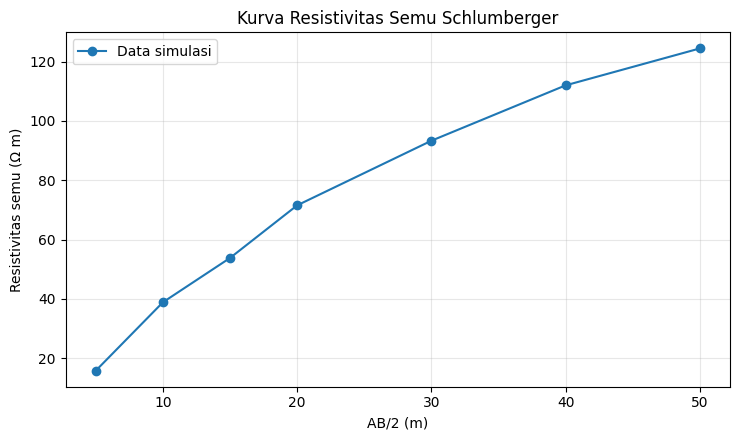

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AB = np.array([10, 20, 30, 40, 60, 80, 100], dtype=float)  # m
MN = np.array([2, 2, 4, 4, 6, 8, 10], dtype=float)          # m
current = np.array([0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10])  # A
voltage = np.array([0.042, 0.025, 0.031, 0.023, 0.020, 0.018, 0.016])  # V

K = np.pi * ((AB / 2)**2 - (MN / 2)**2) / MN
rho_a = K * voltage / current

hasil = pd.DataFrame({
    'AB/2 (m)': AB / 2,
    'MN (m)': MN,
    'K (m)': K,
    'Delta V (V)': voltage,
    'I (A)': current,
    'Resistivitas semu (ohm m)': rho_a
})
display(hasil.round(2))

plt.figure(figsize=(7.5, 4.5))
plt.plot(AB / 2, rho_a, 'o-', label='Data simulasi')
plt.xlabel('AB/2 (m)')
plt.ylabel('Resistivitas semu (Ω m)')
plt.title('Kurva Resistivitas Semu Schlumberger')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### C. Pembahasan Hasil & Verifikasi Mutu Prompt

1. **Analisis hasil:** Resistivitas semu berubah mengikuti jarak bentangan elektroda. Perubahan ini dapat menunjukkan adanya variasi sifat listrik bawah permukaan, tetapi juga dipengaruhi oleh faktor geometri dan susunan lapisan.
2. **Makna geologi:** Material lempung jenuh air umumnya dapat menunjukkan resistivitas lebih rendah dibanding batuan kompak yang relatif kering. Interpretasi tetap memerlukan konteks geologi dan, bila tersedia, inversi data.
3. **Pengecekan mutu (Q & V):**
   - [x] Faktor geometri dihitung dalam meter.
   - [x] Resistivitas semu dihitung dari \(K\Delta V/I\).
   - [x] Nilai simulasi tidak diperlakukan sebagai model resistivitas sebenarnya.

# ANALISIS FREKUENSI REKAMAN GETARAN MENGGUNAKAN FFT

### A. Latar Belakang Teori & Konsep Fisis
Rekaman getaran atau sinyal seismik umumnya dinyatakan sebagai amplitudo terhadap waktu. Transformasi Fourier mengubah representasi dari domain waktu menjadi domain frekuensi sehingga komponen periodik yang dominan dapat dikenali.

Untuk sampel diskret \(x_n\), Discrete Fourier Transform (DFT) dinyatakan sebagai:

\[
X_k=\sum_{n=0}^{N-1}x_n e^{-i2\pi kn/N}
\]

Fast Fourier Transform (FFT) merupakan algoritma efisien untuk menghitung DFT. Resolusi frekuensi bergantung pada lama rekaman, sedangkan frekuensi Nyquist adalah setengah frekuensi sampling.

### B. Prompt AI (Struktur R–T–C–I–K–O–Q–V)

```markdown
# R — Role
Anda adalah tutor pengolahan sinyal seismologi tingkat dasar.

# T — Task
Bangun sinyal getaran campuran dan identifikasi frekuensi dominannya dengan FFT.

# C — Context
Sinyal simulasi terdiri dari dua sinusoid dan noise kecil.

# I — Input
Frekuensi sampling, durasi rekaman, frekuensi komponen, dan amplitudo.

# K — Constraints
Gunakan spektrum satu sisi, tampilkan frekuensi dalam Hz, dan jelaskan batas Nyquist.

# O — Output
Grafik domain waktu, spektrum amplitudo, serta frekuensi puncak.

# Q — Quality Criteria
Sumbu dan satuan benar; hasil dapat direproduksi.

# V — Verification
Frekuensi puncak harus berada dekat frekuensi yang ditanamkan pada sinyal.
```

Tiga puncak spektrum terbesar:
Frekuensi = 4.00 Hz, amplitudo = 1.198
Frekuensi = 12.00 Hz, amplitudo = 0.598
Frekuensi = 40.95 Hz, amplitudo = 0.031
Frekuensi Nyquist = 50.0 Hz


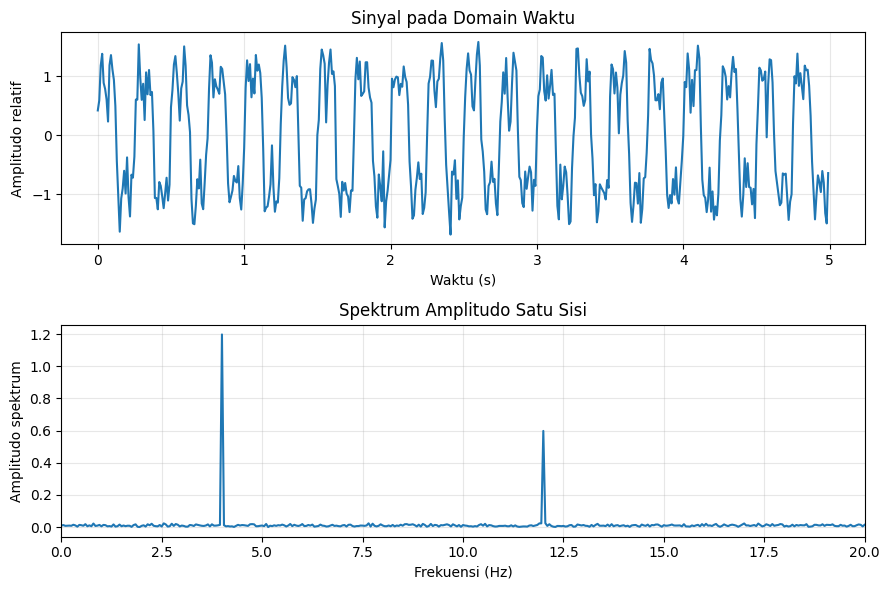

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fs = 100.0                 # frekuensi sampling (Hz)
duration = 20.0            # durasi rekaman (s)
t = np.arange(0, duration, 1/fs)
np.random.seed(7)

signal = (1.2 * np.sin(2*np.pi*4.0*t)
          + 0.6 * np.sin(2*np.pi*12.0*t)
          + 0.25 * np.random.normal(size=t.size))

N = len(signal)
freq = np.fft.rfftfreq(N, d=1/fs)
spectrum = np.abs(np.fft.rfft(signal)) * 2 / N
spectrum[0] /= 2
if N % 2 == 0:
    spectrum[-1] /= 2

# Cari tiga puncak tertinggi selain komponen DC
valid = freq > 0
peak_indices = np.argsort(spectrum[valid])[-3:]
valid_freq = freq[valid]
valid_amp = spectrum[valid]
peaks = sorted(zip(valid_amp[peak_indices], valid_freq[peak_indices]), reverse=True)

print("Tiga puncak spektrum terbesar:")
for amp, f in peaks:
    print(f"Frekuensi = {f:.2f} Hz, amplitudo = {amp:.3f}")
print(f"Frekuensi Nyquist = {fs/2:.1f} Hz")

fig, ax = plt.subplots(2, 1, figsize=(9, 6))
ax[0].plot(t[:500], signal[:500])
ax[0].set_xlabel('Waktu (s)')
ax[0].set_ylabel('Amplitudo relatif')
ax[0].set_title('Sinyal pada Domain Waktu')
ax[0].grid(True, alpha=0.3)

ax[1].plot(freq, spectrum)
ax[1].set_xlim(0, 20)
ax[1].set_xlabel('Frekuensi (Hz)')
ax[1].set_ylabel('Amplitudo spektrum')
ax[1].set_title('Spektrum Amplitudo Satu Sisi')
ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### C. Pembahasan Hasil & Verifikasi Mutu Prompt

1. **Analisis hasil:** Spektrum memperlihatkan puncak di sekitar 4 Hz dan 12 Hz, sesuai komponen yang sengaja dimasukkan ke dalam sinyal. Noise menyebabkan munculnya amplitudo kecil pada frekuensi lain.
2. **Makna pengolahan:** FFT membantu memeriksa kandungan frekuensi, tetapi tidak menunjukkan kapan suatu frekuensi muncul. Untuk sinyal yang berubah terhadap waktu, analisis seperti spektrogram dapat menjadi langkah lanjutan.
3. **Pengecekan mutu (Q & V):**
   - [x] Frekuensi sampling 100 Hz menghasilkan frekuensi Nyquist 50 Hz.
   - [x] Spektrum ditampilkan pada rentang frekuensi yang relevan.
   - [x] Puncak dibandingkan dengan frekuensi sumber sinyal simulasi.

#  ESTIMASI GRADIEN GEOTERMAL DAN ALIRAN PANAS

### A. Latar Belakang Teori & Konsep Fisis
Gradien geotermal menyatakan perubahan suhu terhadap kedalaman. Untuk pendekatan konduksi satu dimensi, hukum Fourier menyatakan:

\[
q=-k\frac{dT}{dz}
\]

dengan \(q\) adalah densitas aliran panas (W/m²), \(k\) konduktivitas termal (W/m K), dan \(dT/dz\) gradien suhu (K/m). Jika suhu meningkat secara hampir linear terhadap kedalaman, gradien dapat diperkirakan melalui regresi linear. Tanda negatif pada hukum Fourier menunjukkan aliran panas bergerak dari suhu tinggi ke suhu rendah.

### B. Prompt AI (Struktur R–T–C–I–K–O–Q–V)

```markdown
# R — Role
Anda adalah asisten praktikum geofisika panas bumi.

# T — Task
Estimasi gradien geotermal dan aliran panas dari data suhu terhadap kedalaman.

# C — Context
Data merupakan contoh sintetis profil temperatur sumur dangkal.

# I — Input
Kedalaman, suhu terukur, dan konduktivitas termal batuan.

# K — Constraints
Gunakan regresi linear, ubah gradien ke K/m sebelum menghitung aliran panas, dan nyatakan asumsi konduktivitas konstan.

# O — Output
Tabel data, gradien suhu, estimasi aliran panas, dan grafik regresi.

# Q — Quality Criteria
Satuan harus konsisten dan ketidakpastian sederhana dibahas.

# V — Verification
Pastikan suhu meningkat dengan kedalaman pada contoh ini dan nilai aliran panas berada pada satuan mW/m².
```

,Kedalaman (m),Suhu (°C),Suhu hasil regresi (°C),Residual (°C)
0,20.0,22.554,22.573,-0.020
1,40.0,23.107,23.122,-0.015
2,60.0,23.805,23.670,0.135
3,80.0,24.089,24.219,-0.130
4,100.0,24.889,24.768,0.122
5,120.0,25.155,25.316,-0.161
6,140.0,25.895,25.865,0.031
7,160.0,26.452,26.413,0.039


Gradien geotermal = 27.43 °C/km
Konduktivitas termal = 2.20 W/(m K)
Estimasi aliran panas = 60.34 mW/m²
RMSE regresi = 0.099 °C


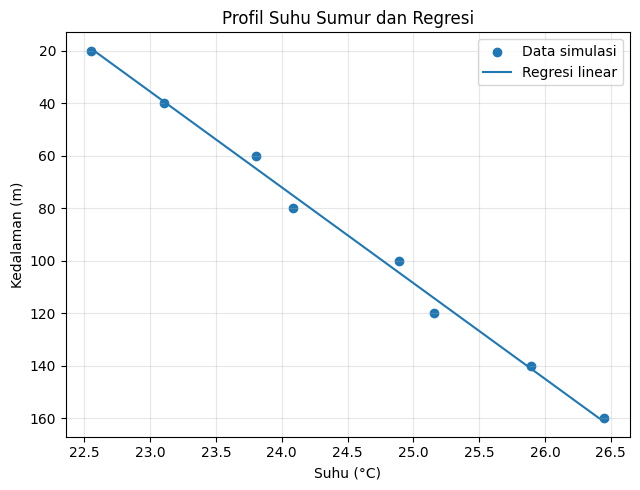

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

depth_m = np.array([20, 40, 60, 80, 100, 120, 140, 160], dtype=float)
np.random.seed(21)
temperature_c = 22.0 + 0.028 * depth_m + np.random.normal(0, 0.12, len(depth_m))
conductivity = 2.2  # W/(m K), diasumsikan konstan

# Regresi: T = gradient * z + intercept
gradient_c_per_m, intercept_c = np.polyfit(depth_m, temperature_c, 1)
heat_flow_w_m2 = conductivity * gradient_c_per_m
heat_flow_mw_m2 = heat_flow_w_m2 * 1000

predicted = gradient_c_per_m * depth_m + intercept_c
residual = temperature_c - predicted
rmse = np.sqrt(np.mean(residual**2))

data = pd.DataFrame({
    'Kedalaman (m)': depth_m,
    'Suhu (°C)': temperature_c,
    'Suhu hasil regresi (°C)': predicted,
    'Residual (°C)': residual
})
display(data.round(3))

print(f"Gradien geotermal = {gradient_c_per_m*1000:.2f} °C/km")
print(f"Konduktivitas termal = {conductivity:.2f} W/(m K)")
print(f"Estimasi aliran panas = {heat_flow_mw_m2:.2f} mW/m²")
print(f"RMSE regresi = {rmse:.3f} °C")

plt.figure(figsize=(6.5, 5))
plt.scatter(temperature_c, depth_m, label='Data simulasi')
plt.plot(predicted, depth_m, label='Regresi linear')
plt.gca().invert_yaxis()
plt.xlabel('Suhu (°C)')
plt.ylabel('Kedalaman (m)')
plt.title('Profil Suhu Sumur dan Regresi')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### C. Pembahasan Hasil & Verifikasi Mutu Prompt

1. **Analisis hasil:** Kemiringan garis regresi menunjukkan kenaikan suhu rata-rata per meter. Nilai tersebut dikonversi menjadi °C/km agar lebih mudah dibandingkan dengan profil geotermal.
2. **Estimasi aliran panas:** Dengan asumsi konduktivitas termal konstan, besar aliran panas dihitung dari \(q=k(dT/dz)\). Perhitungan ini mengabaikan perubahan konduktivitas terhadap kedalaman, aliran fluida, serta sumber panas lokal.
3. **Pengecekan mutu (Q & V):**
   - [x] Gradien dikonversi dari °C/m menjadi °C/km untuk pelaporan.
   - [x] Aliran panas dilaporkan dalam mW/m².
   - [x] Residual dan RMSE digunakan sebagai pemeriksaan sederhana terhadap kecocokan regresi.